# Set up the Enviroment

In [13]:
!pip install kagglehub
import kagglehub
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score)

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Downlaod and Prepare the Dataset

In [3]:
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

DATA_DIR = os.path.join(path, 'chest_xray')
TRAIN_DIR = os.path.join(DATA_DIR, 'train')
TEST_DIR = os.path.join(DATA_DIR, 'test')
VAL_DIR = os.path.join(DATA_DIR, 'val')

print(os.listdir(TRAIN_DIR))
print(os.listdir(TEST_DIR))
print(os.listdir(VAL_DIR))

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
['PNEUMONIA', 'NORMAL']
['PNEUMONIA', 'NORMAL']
['PNEUMONIA', 'NORMAL']


# Explore the dataset


In [4]:
def count_images(folder):
  return{
      class_name: len([
          f for f in os.listdir(os.path.join(folder, class_name))
          if f.lower().endswith(('.jpeg','.jpg','.png'))
      ])
      for class_name in ['NORMAL', 'PNEUMONIA']
  }

for name, folder in [
    ('Train', TRAIN_DIR),
    ('Test', TEST_DIR),
    ('Validation', VAL_DIR)
]:
  print(name, count_images(folder))

Train {'NORMAL': 1341, 'PNEUMONIA': 3875}
Test {'NORMAL': 234, 'PNEUMONIA': 390}
Validation {'NORMAL': 8, 'PNEUMONIA': 8}


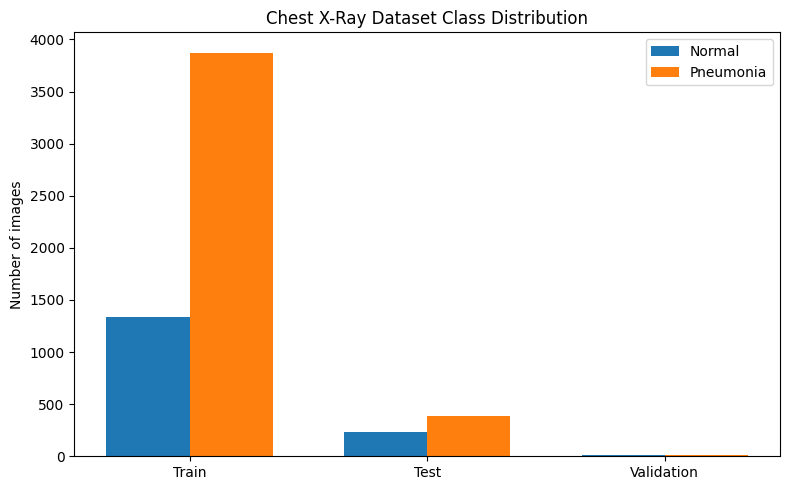

In [5]:
# Visualize Class Distribution
splits = ['Train', 'Test', 'Validation']
folders = [TRAIN_DIR, TEST_DIR, VAL_DIR]

normal_counts = [count_images(f)['NORMAL'] for f in folders]
pneumonia_counts = [count_images(f)['PNEUMONIA'] for f in folders]

x = np.arange(len(splits))
width = 0.35

plt.figure(figsize=(8, 5))
plt.bar(x - width/2, normal_counts, width, label='Normal')
plt.bar(x + width/2, pneumonia_counts, width, label='Pneumonia')

plt.xticks(x, splits)
plt.ylabel('Number of images')
plt.title('Chest X-Ray Dataset Class Distribution')
plt.legend()
plt.tight_layout()
plt.show()

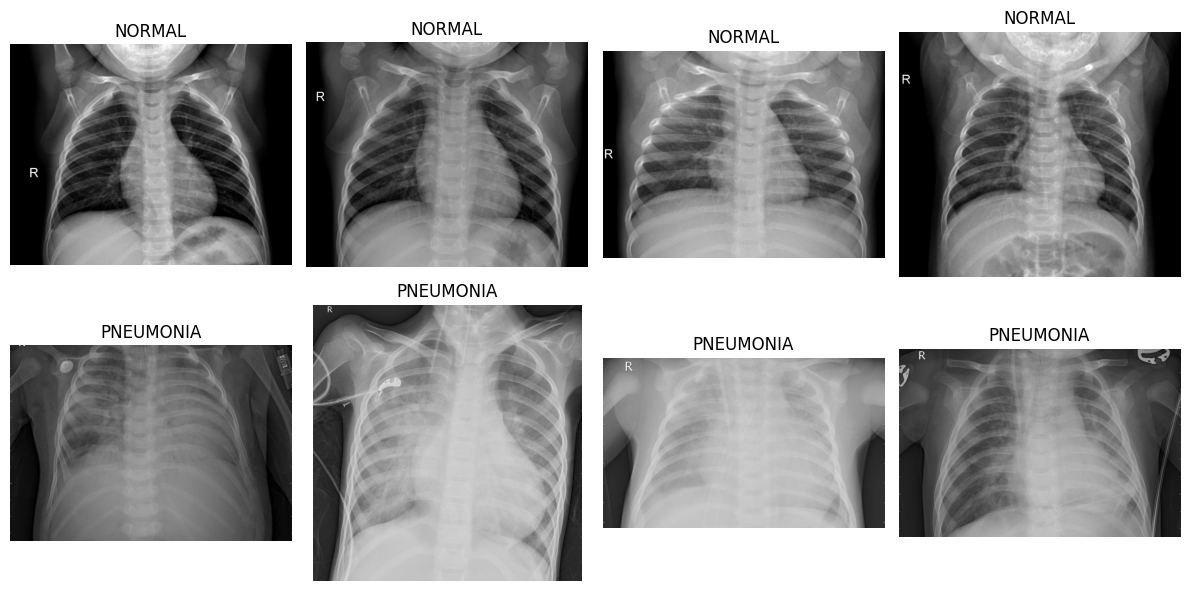

In [6]:
from matplotlib import axes
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for row, class_name in enumerate(['NORMAL', 'PNEUMONIA']):
  folder = os.path.join(TRAIN_DIR, class_name)
  image_files = [
      f for f in os.listdir(folder)
      if f.lower().endswith(('.jpeg', '.jpg', '.png'))
  ]
  random_images = random.sample(image_files, min(4, len(image_files)))

  for col, filename in enumerate(random_images):
    image = tf.keras.utils.load_img(
        os.path.join(folder, filename),
        color_mode='grayscale',
    )
    axes[row, col].imshow(image, cmap='gray')
    axes[row, col].axis('off')
    axes[row, col].set_title(class_name)

plt.tight_layout()
plt.show()

# Preprocess the images

In [7]:
IMG_SIZE = (150, 150)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    class_names=['NORMAL', 'PNEUMONIA'],
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    color_mode='grayscale',
    label_mode='binary',
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    class_names=['NORMAL', 'PNEUMONIA'],
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
    color_mode='grayscale',
    label_mode='binary',
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    class_names=['NORMAL', 'PNEUMONIA'],
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False,
    color_mode='grayscale',
    label_mode='binary',
)

print('Class mapping:', train_ds.class_names)

Found 5216 files belonging to 2 classes.
Found 16 files belonging to 2 classes.
Found 624 files belonging to 2 classes.
Class mapping: ['NORMAL', 'PNEUMONIA']


In [8]:
# Normalize the Images
normalization = layers.Rescaling(1.0/255.0)

train_ds = train_ds.map(lambda x, y: (normalization(x), y), num_parallel_calls=tf.data.AUTOTUNE)
val_ds = val_ds.map(lambda x, y: (normalization(x), y), num_parallel_calls=tf.data.AUTOTUNE)
test_ds = test_ds.map(lambda x, y: (normalization(x), y), num_parallel_calls=tf.data.AUTOTUNE)

train_ds = train_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)

# Apply Data Augmentation

In [9]:
augmentation = models.Sequential([
    layers.RandomRotation(0.04, seed=42),
    layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05,
        seed=42,
    ),
    layers.RandomZoom(0.08, seed=42)
], name='augmentation')

# CNN Model

In [10]:
model = models.Sequential([
   layers.Input(shape=(150, 150, 1)),

   augmentation,

   layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
   layers.MaxPooling2D((2, 2)),

   layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
   layers.MaxPooling2D((2, 2)),

   layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
   layers.MaxPooling2D((2, 2)),

   layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
   layers.MaxPooling2D((2, 2)),

   layers.Flatten(),

   layers.Dense(128, activation='relu'),
   layers.Dropout(0.5),

   layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 150, 150, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 18, 18, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 9, 9, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 10368)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,327,232 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,567,617 (5.98 MB)

 Trainable params: 1,567,617 (5.98 MB)

 Non-trainable params: 0 (0.00 B)

# Class Imbalance Handeling

In [11]:
counts = count_images(TRAIN_DIR)
n_normal = counts["NORMAL"]
n_pneumonia = counts["PNEUMONIA"]
n_total = n_normal + n_pneumonia

class_weights = {
    0: n_total / (2 * n_normal),
    1: n_total / (2 * n_pneumonia)
}

print("Training counts:", counts)
print("Class weights:", class_weights)

Training counts: {'NORMAL': 1341, 'PNEUMONIA': 3875}
Class weights: {0: 1.9448173005219984, 1: 0.6730322580645162}


# Model Training

In [14]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    class_weight=class_weights,
    callbacks=[early_stopping]
)

Epoch 1/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 42s 201ms/step - accuracy: 0.7234 - loss: 0.4473 - precision: 0.9349 - recall: 0.6746 - val_accuracy: 0.7500 - val_loss: 0.3457 - val_precision: 0.6667 - val_recall: 1.0000
Epoch 2/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - accuracy: 0.9183 - loss: 0.2174 - precision: 0.9734 - recall: 0.9151 - val_accuracy: 0.6875 - val_loss: 0.4499 - val_precision: 0.6154 - val_recall: 1.0000
Epoch 3/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - accuracy: 0.9362 - loss: 0.1717 - precision: 0.9781 - recall: 0.9350 - val_accuracy: 0.7500 - val_loss: 0.8162 - val_precision: 0.6667 - val_recall: 1.0000
Epoch 4/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - accuracy: 0.9436 - loss: 0.1473 - precision: 0.9830 - recall: 0.9404 - val_accuracy: 0.9375 - val_loss: 0.2196 - val_precision: 1.0000 - val_recall: 0.8750
Epoch 5/25
163/163 ━━━━━━━━━━━━━━━━━━━━ 4s 27ms/step - accuracy: 0.9434 - loss: 0.1437 - precision: 0.9827 - recall: 0.9404 - val_accuracy: 0.8125 - val_l

# Accuracy and Loss Curves

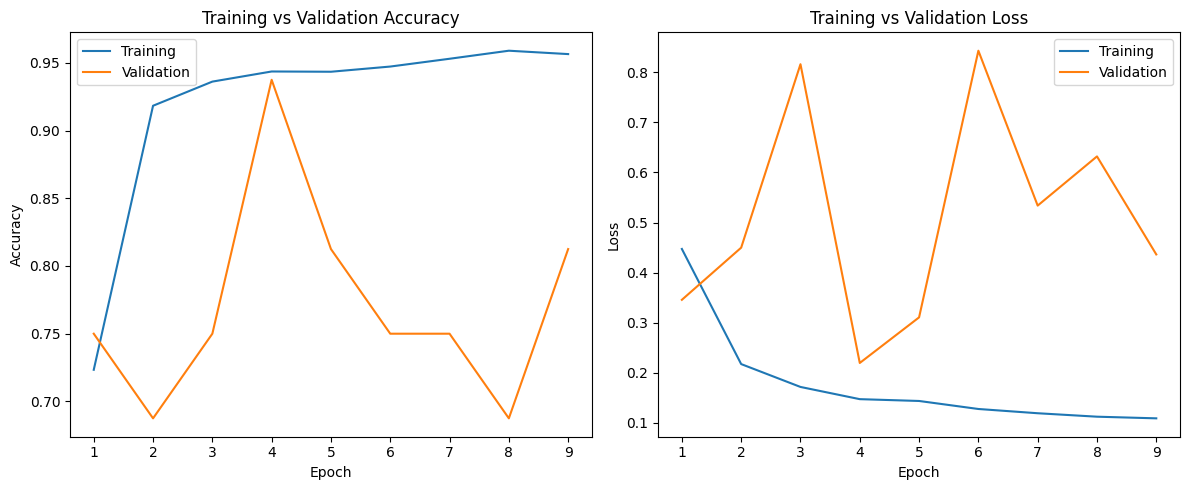

In [15]:
epochs_range = range(1, len(history.history["loss"]) + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, history.history["accuracy"], label="Training")
plt.plot(epochs_range, history.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, history.history["loss"], label="Training")
plt.plot(epochs_range, history.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()

plt.tight_layout()
plt.show()

Intepretation:
* Both accuracy curves improve and converge: potentially healthy learning.
* Training accuracy rises while validation accuracy stagnates: possible overfitting.
* Both accuracy curves remain low: possible underfitting or optimization problems.
* Validation loss rises while training loss falls: a common sign of overfitting.

# Evaluation

In [17]:
y_true = np.concatenate([
    labels.numpy().ravel()
    for _, labels in test_ds
]).astype(int)

y_prob = model.predict(test_ds, verbose=1).ravel()

# Default classification threshold
y_pred = (y_prob >= 0.5).astype(int)

#Evaluation Matrics
print("Accuracy:", accuracy_score(y_true, y_pred))
print("Precision:", precision_score(y_true, y_pred, zero_division=0))
print("Recall:", recall_score(y_true, y_pred, zero_division=0))
print("F1-score:", f1_score(y_true, y_pred, zero_division=0))

print("\nClassification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["NORMAL", "PNEUMONIA"],
    zero_division=0
))

20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
Accuracy: 0.8541666666666666
Precision: 0.8257080610021786
Recall: 0.9717948717948718
F1-score: 0.8928150765606596

Classification Report:

              precision    recall  f1-score   support

      NORMAL       0.93      0.66      0.77       234
   PNEUMONIA       0.83      0.97      0.89       390

    accuracy                           0.85       624
   macro avg       0.88      0.81      0.83       624
weighted avg       0.87      0.85      0.85       624



# Confusion Matix

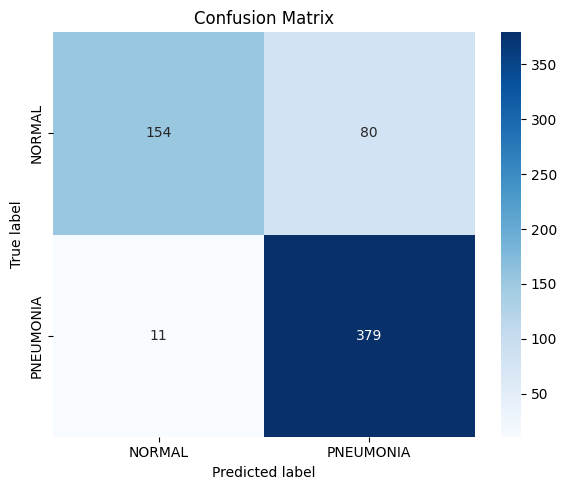

In [18]:
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["NORMAL", "PNEUMONIA"],
    yticklabels=["NORMAL", "PNEUMONIA"]
)

plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

Interpretation:
* True negative: NORMAL correctly predicted as NORMAL.
* False positive: NORMAL incorrectly predicted as PNEUMONIA.
* False negative: PNEUMONIA incorrectly predicted as NORMAL.
* True positive: PNEUMONIA correctly predicted as PNEUMONIA.

# Transfer Learning

In [20]:
IMG_SIZE_TL = (224, 224)
BATCH_SIZE_TL = 32

train_tl = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    class_names=["NORMAL", "PNEUMONIA"],
    image_size=IMG_SIZE_TL,
    color_mode="rgb",
    batch_size=BATCH_SIZE_TL,
    label_mode="binary",
    seed=42
)

val_tl = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    class_names=["NORMAL", "PNEUMONIA"],
    image_size=IMG_SIZE_TL,
    color_mode="rgb",
    batch_size=BATCH_SIZE_TL,
    label_mode="binary",
    shuffle=False
)

test_tl = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    class_names=["NORMAL", "PNEUMONIA"],
    image_size=IMG_SIZE_TL,
    color_mode="rgb",
    batch_size=BATCH_SIZE_TL,
    label_mode="binary",
    shuffle=False
)

#Pretrained feature Extractor
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))

x = layers.RandomRotation(0.03)(inputs)
x = layers.RandomZoom(0.05)(x)

# MobileNetV2 preprocessing maps pixels to [-1, 1]
x = layers.Rescaling(
    scale=1./127.5,
    offset=-1
)(x)

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

transfer_model = models.Model(inputs, outputs)

transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy", tf.keras.metrics.Precision(),
             tf.keras.metrics.Recall()]
)

transfer_history = transfer_model.fit(
    train_tl,
    validation_data=val_tl,
    epochs=10,
    class_weight=class_weights,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        )
    ]
)

Found 5216 files belonging to 2 classes.
Found 16 files belonging to 2 classes.
Found 624 files belonging to 2 classes.
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 37s 197ms/step - accuracy: 0.8669 - loss: 0.3103 - precision_1: 0.9525 - recall_1: 0.8640 - val_accuracy: 0.8125 - val_loss: 0.2792 - val_precision_1: 0.7273 - val_recall_1: 1.0000
Epoch 2/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 38s 184ms/step - accuracy: 0.9287 - loss: 0.1802 - precision_1: 0.9803 - recall_1: 0.9226 - val_accuracy: 0.8125 - val_loss: 0.2758 - val_precision_1: 0.7273 - val_recall_1: 1.0000
Epoch 3/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 31s 187ms/step - accuracy: 0.9352 - loss: 0.1550 - precision_1: 0.9825 - recall_1: 0.9293 - val_accuracy: 0.8125 - val_loss: 0.3057 - val_precision_1: 0.7273 - val_recall_1: 1.0000
Epoch 4/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 30s 185ms/step - accuracy: 0.9434 - loss: 0.1400 - precision_1: 0.9838 - recall_1: 0.9394 - val_accuracy: 0.8750 - val_loss: 0.2